# Day 6 · Multi-Layer Perceptrons
`nn.Module` with two hidden layers classifying **soil type** from the other columns; accuracy tracked per epoch.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("crop_yield.csv")          # put crop_yield.csv next to this notebook
print(df.shape)
df.head()

(1000000, 10)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [2]:
import torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("device:", device)
torch.manual_seed(42)

sub = df.sample(100_000, random_state=42).reset_index(drop=True)      # subsample keeps CPU training quick
classes = sorted(sub["Soil_Type"].unique()); print("soil classes:", classes)
y = sub["Soil_Type"].map({c: i for i, c in enumerate(classes)}).to_numpy()
X = pd.get_dummies(sub.drop(columns=["Soil_Type"]), columns=["Region", "Crop", "Weather_Condition"]).astype(float).to_numpy()
cut = int(0.8 * len(sub))
sc = StandardScaler().fit(X[:cut])
Xtr = torch.tensor(sc.transform(X[:cut]), dtype=torch.float32).to(device); ytr = torch.tensor(y[:cut]).to(device)
Xte = torch.tensor(sc.transform(X[cut:]), dtype=torch.float32).to(device); yte = torch.tensor(y[cut:]).to(device)
print("chance accuracy ~", round(1 / len(classes), 3))

def train(model, epochs, bs=512, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr); lossf = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "train_acc": [], "test_acc": []}
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), device=device); tot = 0.0
        for i in range(0, len(Xtr), bs):
            b = perm[i:i+bs]; opt.zero_grad(); loss = lossf(model(Xtr[b]), ytr[b]); loss.backward(); opt.step(); tot += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            tr_acc = (model(Xtr).argmax(1) == ytr).float().mean().item(); te_acc = (model(Xte).argmax(1) == yte).float().mean().item()
        hist["train_loss"].append(tot / len(Xtr)); hist["train_acc"].append(tr_acc); hist["test_acc"].append(te_acc)
        if ep % 5 == 0 or ep == epochs - 1: print(f"epoch {ep:2d}  loss {hist['train_loss'][-1]:.4f}  train acc {tr_acc:.3f}  test acc {te_acc:.3f}")
    return hist

device: cpu
soil classes: ['Chalky', 'Clay', 'Loam', 'Peaty', 'Sandy', 'Silt']
chance accuracy ~ 0.167


In [3]:
class SoilMLP(nn.Module):
    def __init__(self, d_in, n_classes):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, n_classes))
    def forward(self, x): return self.net(x)

model = SoilMLP(Xtr.shape[1], len(classes)).to(device)
hist = train(model, epochs=20)

epoch  0  loss 1.7934  train acc 0.174  test acc 0.169


epoch  5  loss 1.7900  train acc 0.185  test acc 0.169


epoch 10  loss 1.7882  train acc 0.193  test acc 0.165


epoch 15  loss 1.7862  train acc 0.200  test acc 0.167


epoch 19  loss 1.7844  train acc 0.202  test acc 0.166


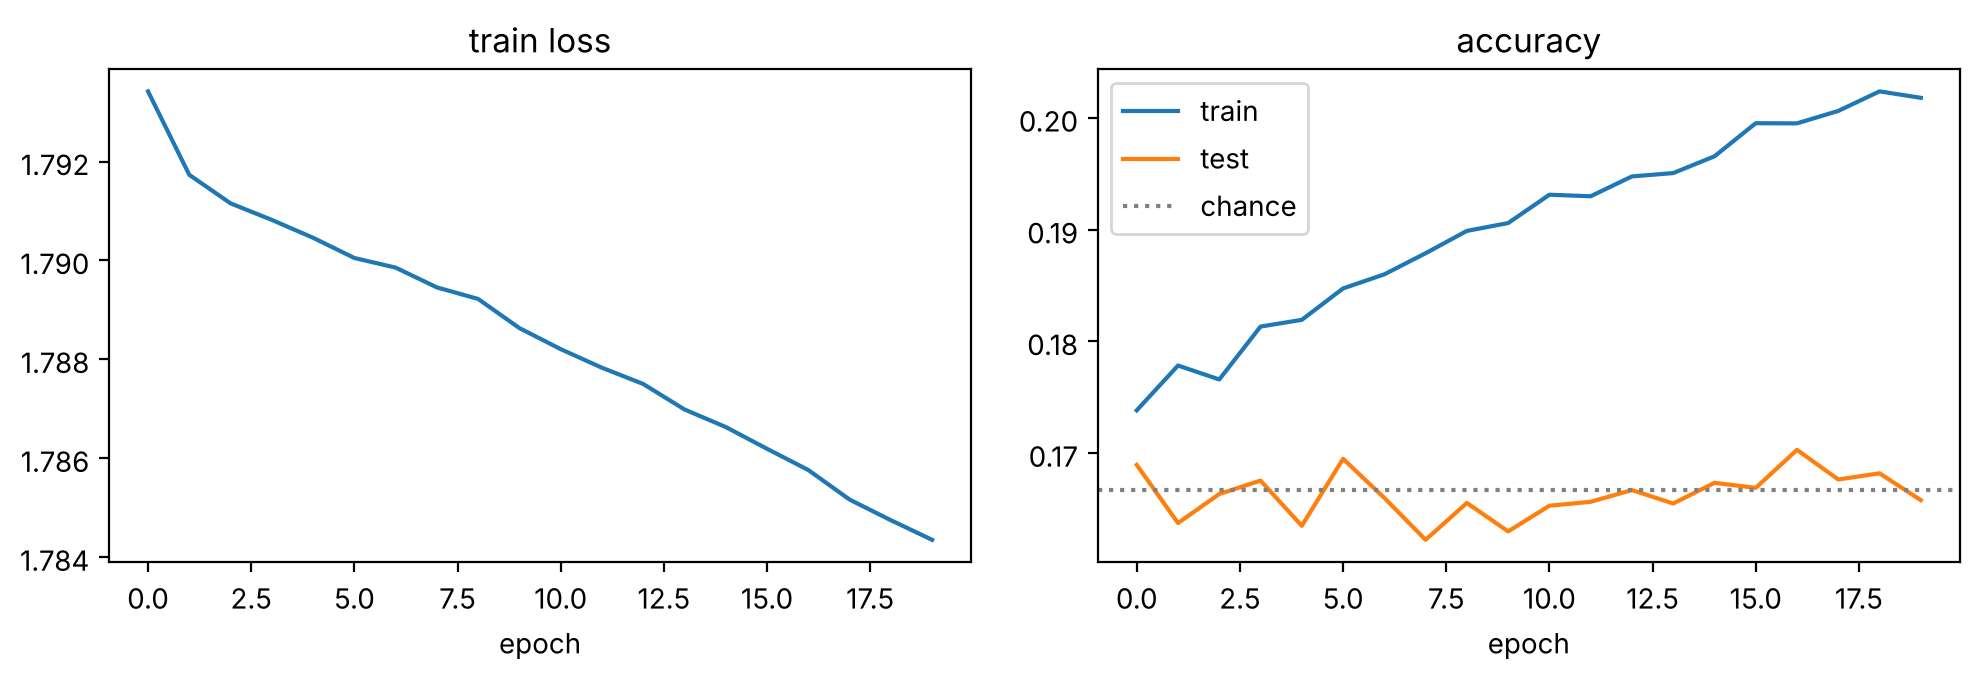

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["train_loss"]); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["train_acc"], label="train"); ax[1].plot(hist["test_acc"], label="test"); ax[1].axhline(1/len(classes), color="gray", ls=":", label="chance")
ax[1].set_title("accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); plt.tight_layout(); plt.show()

**Reading the result:** test accuracy stays near chance (1/6 ≈ 0.167). That is a property of this dataset, not a bug: soil type is statistically independent of the other columns, so there is no signal to learn. The train-vs-test gap is the thing to watch here (the model memorises noise), and that is what the Day 7 regularisation comparison shows.